# code_188 · Scores describe different prediction objects

**Book:** section 36.1. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_36_GUIDE.md), [execution evidence](../CHAPTER_36_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_188).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evaluation contracts identify the population, sampling unit, available information, score direction and decision consequences. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7788;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7788


<a id="point-and-quantile-scores"></a>
 ## Fit predictions and choose the reporting contract before final assessment
 Independent source 1,000 and final 600 structures have normalized load and material variation. Generated deflection is measured in millimetres, with nonlinear mean, load-dependent noise and occasional large positive disturbances. Source-only Ridge and histogram boosting predict a mean-like point; three separately fitted native histogram quantile models predict levels 0.1, 0.5 and 0.9. All recipes and the operational weight 4 for loads above 1.3 are fixed before final observations. No final result selects a recipe. MAE/RMSE, a relative error with an explicit 1 mm denominator floor, weighted RMSE and an asymmetric cost answer different questions. A 0.9 quantile is not a claim to be the conditional mean. Quantile fits can cross; report raw crossing before sorting for a stated interval-only summary.


,MAE_mm,RMSE_mm,relative_floor1,weighted_RMSE_mm,asymmetric_under_cost_mm
Ridge,0.745230,1.355648,0.203438,1.591289,1.811417
Boost,0.689311,1.337864,0.179958,1.586742,1.696220


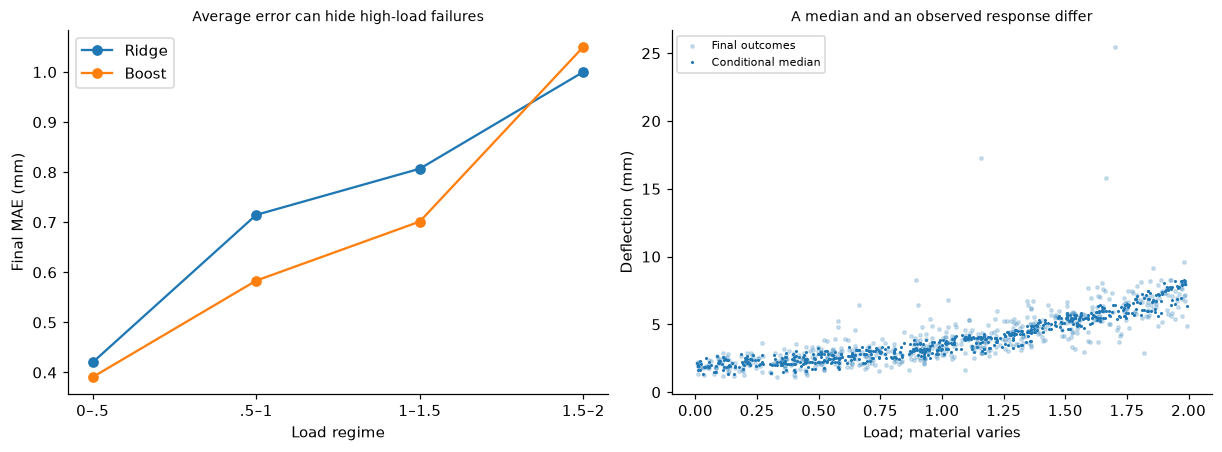

In [2]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
def cohort(n):
    x=np.c_[rng.uniform(0,2,n),rng.normal(size=n)];mu=2+1.4*x[:,0]**2+.3*x[:,1];scale=.25+.45*x[:,0];y=mu+scale*rng.normal(size=n)+(rng.random(n)<.04)*rng.exponential(3,n);return x,y
xs,ys=cohort(1000);xf,yf=cohort(600);models={'Ridge':Ridge(alpha=1),'Boost':HistGradientBoostingRegressor(max_iter=120,max_depth=3,learning_rate=.08,early_stopping=False,random_state=SEED)};pred={name:m.fit(xs,ys).predict(xf) for name,m in models.items()};w=np.where(xf[:,0]>1.3,4.,1.)
def metrics(p):
    e=p-yf;return {'MAE_mm':float(np.mean(abs(e))),'RMSE_mm':float(np.sqrt(np.mean(e*e))),'relative_floor1':float(np.mean(abs(e)/np.maximum(abs(yf),1))),'weighted_RMSE_mm':float(np.sqrt(np.sum(w*e*e)/w.sum())),'asymmetric_under_cost_mm':float(np.mean(np.maximum(e,0)+4*np.maximum(-e,0)))}
point={k:metrics(v) for k,v in pred.items()};levels=[.1,.5,.9];q=np.column_stack([HistGradientBoostingRegressor(loss='quantile',quantile=t,max_iter=120,max_depth=3,early_stopping=False,random_state=SEED).fit(xs,ys).predict(xf) for t in levels]);pinball=[float(np.mean(np.maximum(t*(yf-q[:,j]),(t-1)*(yf-q[:,j])))) for j,t in enumerate(levels)];cross=float(np.mean(np.any(np.diff(q,axis=1)<0,axis=1)));ordered=np.sort(q,axis=1);coverage=float(np.mean((yf>=ordered[:,0])&(yf<=ordered[:,2])));width=float(np.mean(ordered[:,2]-ordered[:,0]));assert len(xf)==600 and np.all(w>0);assert np.isclose(point['Boost']['weighted_RMSE_mm']**2,np.average((pred['Boost']-yf)**2,weights=w));assert all(v>=0 for v in pinball)
RESULTS.update(source_records=1000,final_records=600,point_scores=point,quantile_levels=levels,pinball_mm=pinball,raw_crossing_fraction=cross,sorted_interval_coverage=coverage,sorted_interval_width_mm=width,relative_denominator_floor_mm=1,large_load_weight=4)
display(pd.DataFrame(point).T);fig,axes=plt.subplots(1,2,figsize=(11,4));bins=np.digitize(xf[:,0],[.5,1,1.5]);
for name,p in pred.items():axes[0].plot(range(4),[np.mean(abs(p[bins==b]-yf[bins==b])) for b in range(4)],'o-',label=name)
axes[0].set(xticks=range(4),xticklabels=['0–.5','.5–1','1–1.5','1.5–2'],xlabel='Load regime',ylabel='Final MAE (mm)',title='Average error can hide high-load failures');axes[0].legend();order=np.argsort(xf[:,0]);axes[1].scatter(xf[:,0],yf,s=5,alpha=.2,label='Final outcomes');axes[1].plot(xf[order,0],ordered[order,1],'.',markersize=2,label='Conditional median');axes[1].set(xlabel='Load; material varies',ylabel='Deflection (mm)',title='A median and an observed response differ');axes[1].legend(fontsize=7);plt.show()


<a id="proper-distribution-scores"></a>
 ## Score uncertainty rather than reward width alone
 Fit a single source residual standard deviation around the fitted booster and retain its source mean predictor. Compare that Gaussian forecast with an explicitly overwide forecast using twice the same source scale. This is a misspecified distributional approximation, not a true conditional law. Evaluate Gaussian negative log density and the closed-form Gaussian CRPS (lower is better), alongside central 80% coverage and width. Source residual scale can itself be optimistic; no final recalibration is performed. Independently check CRPS for one final point by numerical integration of the squared CDF error. Scores use millimetres except log density, whose numeric value depends on the declared measurement unit.


,Gaussian_NLL,CRPS_mm,coverage80,width80_mm
Source scale,1.770275,0.538054,0.900000,2.732884
Twice source scale,1.873024,0.687887,0.983333,5.465768


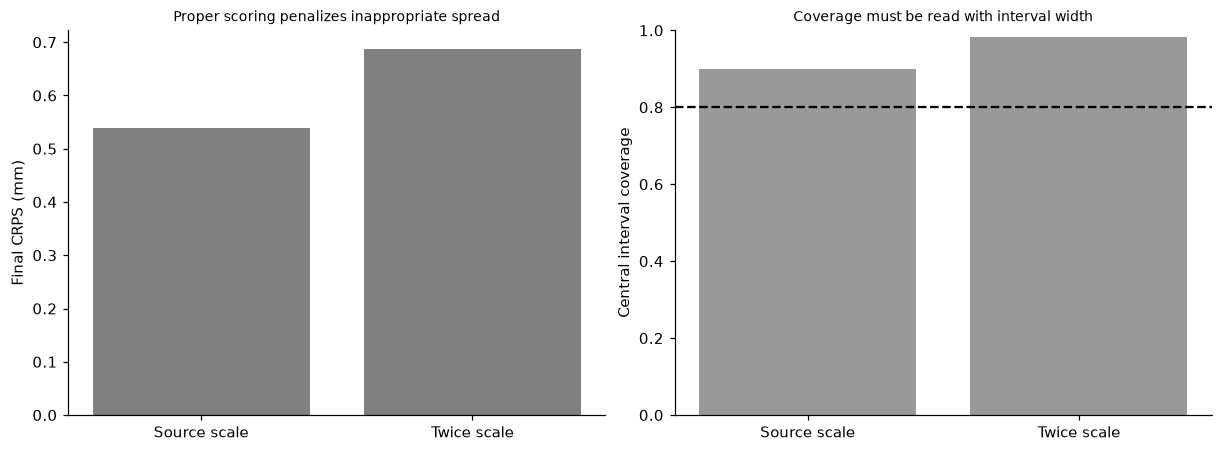

In [3]:
from scipy.stats import norm
from scipy.integrate import quad
sigma=float(np.sqrt(np.mean((models['Boost'].predict(xs)-ys)**2)));assert sigma>0;mu=pred['Boost'];dist={}
def crps(y,m,s):
    z=(y-m)/s;return s*(z*(2*norm.cdf(z)-1)+2*norm.pdf(z)-1/np.sqrt(np.pi))
for name,s in [('Source scale',sigma),('Twice source scale',2*sigma)]:
    z=norm.ppf(.9);dist[name]={'Gaussian_NLL':float(np.mean(-norm.logpdf(yf,mu,s))),'CRPS_mm':float(np.mean(crps(yf,mu,s))),'coverage80':float(np.mean(abs(yf-mu)<=z*s)),'width80_mm':float(2*z*s)}
yi,mi=float(yf[0]),float(mu[0]);lo=min(yi,mi)-12*sigma;hi=max(yi,mi)+12*sigma;numerical=quad(lambda t:norm.cdf((t-mi)/sigma)**2,lo,yi)[0]+quad(lambda t:(norm.cdf((t-mi)/sigma)-1)**2,yi,hi)[0];assert np.isclose(numerical,crps(yi,mi,sigma),atol=1e-8);assert dist['Twice source scale']['width80_mm']==2*dist['Source scale']['width80_mm'];assert np.all(crps(yf,mu,sigma)>=0)
RESULTS.update(source_residual_scale_mm=sigma,distribution_scores=dist,CRPS_numeric_check_error=float(abs(numerical-crps(yi,mi,sigma))));display(pd.DataFrame(dist).T);fig,axes=plt.subplots(1,2,figsize=(11,4));names=list(dist);xx=np.arange(2);axes[0].bar(xx,[dist[k]['CRPS_mm'] for k in names],color='.5');axes[0].set(xticks=xx,xticklabels=['Source scale','Twice scale'],ylabel='Final CRPS (mm)',title='Proper scoring penalizes inappropriate spread');axes[1].bar(xx,[dist[k]['coverage80'] for k in names],color='.6');axes[1].axhline(.8,color='black',linestyle='--');axes[1].set(xticks=xx,xticklabels=['Source scale','Twice scale'],ylim=(0,1),ylabel='Central interval coverage',title='Coverage must be read with interval width');plt.show()


In [4]:
summary={'example_id':'code_188','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual ridge and histogram point predictors with unit-aware weighted metrics', 'actual source-fitted conditional quantiles and pinball loss', 'Gaussian log score CRPS coverage and interval width', 'independent final scores with declared asymmetric underprediction cost'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual ridge and histogram point predictors with unit-aware weighted metrics", "actual source-fitted conditional quantiles and pinball loss", "Gaussian log score CRPS coverage and interval width", "independent final scores with declared asymmetric underprediction cost"], "elapsed_seconds": 0.476, "example_id": "code_188", "hardware": "Darwin arm64 CPU", "results": {"CRPS_numeric_check_error": 1.6653345369377348e-16, "distribution_scores": {"Source scale": {"CRPS_mm": 0.5380539582344304, "Gaussian_NLL": 1.7702747533694416, "coverage80": 0.9, "width80_mm": 2.7328838705548253}, "Twice source scale": {"CRPS_mm": 0.6878868121328933, "Gaussian_NLL": 1.8730238159151782, "coverage80": 0.9833333333333333, "width80_mm": 5.465767741109651}}, "final_records": 600, "large_load_weight": 4, "pinball_mm": [0.12986930316858783, 0.33289349114983396, 0.2284171940636928], "point_scores": {"Boost": {"MAE_mm": 0.6893107352800719, "RMSE_mm": 1.33786392911611